# phasecast inference: whole-rock chemistry in, mineralogy posterior out

This notebook is the reference path for calling the trained model on new rocks.
It is written for someone building an application on top of the model rather
than for someone training it. Everything runs on CPU from the repository root
and finishes in seconds.

What it covers, in order:

1. **Input.** The table a caller supplies: major oxides in wt%, trace elements
   in ppm, nothing else. How it is checked and turned into the model's tokens.
2. **Loading.** The two checkpoint files and what is inside them.
3. **Zero-shot prediction.** The encoder and the three heads, and how a
   posterior over mineral assemblages and formation conditions is sampled.
4. **Recalibration.** The small correction layer fit on measured rocks, how it
   is fit, saved, loaded and applied, so the app can show both arms.
5. **The card.** One figure per rock from the sampled posterior, including the
   temperature-pressure density.
6. **The per-rock record.** The numbers an app ships per rock, as JSON.

The library functions used here are the ones the research scripts use. The
stable inference API (issue #70) will fold most of this notebook into one call;
until then this is the contract.

In [1]:
import cnmineral  # import first: sets KMP_DUPLICATE_LIB_OK before torch loads (macOS OpenMP collision)

import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde

# the heads checkpoint names its encoder by a path relative to the repository root
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "checkpoints").is_dir())
os.chdir(ROOT)
torch.set_num_threads(4)

## 1. Input

One row per rock. The model reads seven major oxides, iron in any one of four
forms, and up to thirteen trace elements. It never reads temperature, pressure,
water content, rock name, LOI, MnO or P2O5; extra columns are ignored.

| columns | unit | required |
|---|---|---|
| `sio2 al2o3 cao mgo k2o na2o tio2` | oxide wt% | yes |
| one of `feo` + `fe2o3`, `feo_tot`, `fe2o3_tot` | oxide wt% | yes |
| `sr_ppm zr_ppm ba_ppm y_ppm rb_ppm ni_ppm nb_ppm v_ppm la_ppm ce_ppm nd_ppm yb_ppm th_ppm` | ppm | no |

A missing trace element is not a zero: the encoder was pretrained with missing
tokens, so a majors-only rock is a valid input. Values are passed through on
the total the source reports; nothing is renormalized to 100. Below-detection
entries from a lab certificate (`<0.5`, `< DL`) should be left blank.

The column lists below come from the tokenizer itself, so this cell cannot
drift from the code.

In [2]:
from cnmineral.data.bulk_chemistry import IRON_SOURCE_COLS, MAJOR_TOKEN_TO_COL, TRACE_TOKEN_TO_COL, tokenize_bulk_frame

MAJOR_COLS = [c for c in MAJOR_TOKEN_TO_COL.values() if c != "cr2o3"]  # Cr2O3 is accepted but left padded in production
TRACE_COLS = list(TRACE_TOKEN_TO_COL.values())
print("majors:", MAJOR_COLS)
print("iron, any one form:", list(IRON_SOURCE_COLS))
print("traces:", TRACE_COLS)

majors: ['sio2', 'al2o3', 'cao', 'mgo', 'k2o', 'na2o', 'tio2']
iron, any one form: ['feo', 'fe2o3', 'feo_tot', 'fe2o3_tot']
traces: ['sr_ppm', 'zr_ppm', 'ba_ppm', 'y_ppm', 'rb_ppm', 'ni_ppm', 'nb_ppm', 'v_ppm', 'la_ppm', 'ce_ppm', 'nd_ppm', 'yb_ppm', 'th_ppm']


Three rocks from the benchmark (du Bray et al., USGS Data Series 764, Bodie
Hills) stand in for a caller's table. The trachybasalt has its trace elements
withheld to show a majors-only input.

In [3]:
samples = pd.read_csv("data/real_mineralogy/samples.csv", dtype={"sample_id": str}).set_index("sample_id")
DEMO = {"12BA32": "trachybasalt", "203181": "trachyandesite", "203105": "rhyolite"}
rocks = samples.loc[list(DEMO), [*MAJOR_COLS, "feo_tot", *TRACE_COLS]].copy()
rocks.index = pd.Index([f"{name} {sid}" for sid, name in DEMO.items()], name="rock")
rocks.loc[rocks.index[0], TRACE_COLS] = np.nan
rocks.round(2)

,sio2,al2o3,cao,mgo,k2o,na2o,tio2,feo_tot,sr_ppm,zr_ppm,...,y_ppm,rb_ppm,ni_ppm,nb_ppm,v_ppm,la_ppm,ce_ppm,nd_ppm,yb_ppm,th_ppm
rock,,,,,,,,,,,,,,,,,,,,,
trachybasalt 12BA32,49.22,17.02,10.11,7.58,2.27,3.26,1.44,7.97,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trachyandesite 203181,59.00,16.48,6.15,4.35,3.33,3.68,0.86,5.72,643.0,188.0,...,19.8,142.0,49.0,9.0,133.0,38.7,74.1,35.0,1.6,15.5
rhyolite 203105,66.31,18.32,3.26,1.13,3.39,4.34,0.36,2.60,1150.0,134.0,...,8.4,51.5,6.0,4.0,34.0,24.4,39.6,21.3,0.8,4.8


The tokenizer does not validate. Two checks belong in front of it: every oxide
within 0 to 100 wt% and every trace within 0 to 1,000,000 ppm (a value past
either bound overflows the encoder's lookup table), and a loose sanity band on
the major-oxide total. The function returns problems instead of raising so an
app can show them all at once.

In [4]:
def check_input(df):
    problems = []
    for c in MAJOR_COLS:
        if c not in df or df[c].isna().all():
            problems.append(f"missing major oxide column {c}")
    if not any(c in df and df[c].notna().any() for c in IRON_SOURCE_COLS):
        problems.append("no iron column (feo + fe2o3, feo_tot, or fe2o3_tot)")
    oxides = df.reindex(columns=[*MAJOR_COLS, *IRON_SOURCE_COLS])
    traces = df.reindex(columns=TRACE_COLS)
    for rock in df.index:
        if ((oxides.loc[rock] < 0) | (oxides.loc[rock] > 100)).any():
            problems.append(f"{rock}: an oxide outside 0-100 wt%")
        if ((traces.loc[rock] < 0) | (traces.loc[rock] > 1e6)).any():
            problems.append(f"{rock}: a trace outside 0-1e6 ppm")
        total = oxides.loc[rock].sum()
        if not 85 <= total <= 103:
            problems.append(f"{rock}: major-oxide total {total:.1f} wt% looks wrong")
    return problems


print(check_input(rocks) or "input ok")

input ok


`tokenize_bulk_frame` turns the table into two arrays of shape `[rocks, 22]`:
`src` holds each token's atomic number (0 marks a padded, missing element) and
`frac` its cation mass fraction. Iron collapses to one Fe token whichever form
it arrived in.

In [5]:
from cnmineral.data.tokens import VOCAB

src, frac = tokenize_bulk_frame(rocks)
print("src", src.shape, src.dtype, " frac", frac.shape, frac.dtype)
tokens = pd.DataFrame({"element": [sym for sym, _ in VOCAB], "atomic_number": src[2], "cation_mass_fraction": frac[2]})
print("tokens for", rocks.index[2])
tokens.T

src (3, 22) int64  frac (3, 22) float32
tokens for rhyolite 203105


,0,1,2,3,4,5,6,7,8,9,...,12,13,14,15,16,17,18,19,20,21
element,Si,Al,Ca,Mg,Fe,K,Na,Ti,Cr,Sr,...,Y,Rb,Ni,Nb,V,La,Ce,Nd,Yb,Th
atomic_number,14,13,20,12,26,19,11,22,0,38,...,39,37,28,41,23,57,58,60,70,90
cation_mass_fraction,0.30998,0.096968,0.023285,0.006842,0.020227,0.028172,0.032203,0.002184,0.0,0.00115,...,0.000008,0.000051,0.000006,0.000004,0.000034,0.000024,0.00004,0.000021,0.000001,0.000005


## 2. Loading the model

Two files, both tracked in git and both plain `torch.save` dictionaries:

- `checkpoints/pretrain_allrock_redox_seed0/epoch_best.pt`, the encoder (44 MB,
  of which the weights are about a third; the rest is optimizer state).
- `checkpoints/joint_heads_allrock_tuned_seed0/heads_best.pt`, the three heads
  (7 MB), which also records the encoder path above, relative to the
  repository root.

No YAML is needed: each file carries the configuration that rebuilds its
module. The element embedding table the encoder reads
(`src/cnmineral/data/element_properties/mat2vec.csv`) ships inside the
package.

In [6]:
from cnmineral.eval.latent import load_encoder_from_checkpoint
from cnmineral.training.joint_heads import JointHeadCheckpoint

t0 = time.perf_counter()
ckpt = JointHeadCheckpoint.load("checkpoints/joint_heads_allrock_tuned_seed0/heads_best.pt")
mode_head, comp_head, cond_head = ckpt.build_mode_head(), ckpt.build_comp_head(), ckpt.build_cond_head()
encoder, _ = load_encoder_from_checkpoint(ckpt.encoder_checkpoint)
encoder.eval()
print(f"loaded in {time.perf_counter() - t0:.2f} s from {ckpt.encoder_checkpoint}")
count = lambda m: sum(p.numel() for p in m.parameters())
print(f"parameters: encoder {count(encoder):,}  mode head {count(mode_head):,}  comp head {count(comp_head):,}  cond head {count(cond_head):,}")

/opt/miniconda3/envs/mineral/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loaded in 0.04 s from checkpoints/pretrain_allrock_redox_seed0/epoch_best.pt
parameters: encoder 3,234,699  mode head 1,346,090  comp head 65,404  cond head 418,843


## 3. Zero-shot prediction

The encoder maps the 22 tokens of a rock to one 256-number vector, its latent.
Every head reads that vector and nothing else:

- **ModeHead** says which of 21 minerals are present (one probability each)
  and, given a mineral list, how much of each (a Dirichlet over the shares).
- **CompHead** gives each mineral's own oxide composition.
- **CondHead** gives temperature, pressure and water content as a small
  mixture per axis, conditioned on the mineral list, so each sampled
  assemblage carries its own conditions.

For display the 21 minerals collapse to the seven groups measured mineralogy
resolves: feldspar, pyroxene, amphibole, biotite, olivine, Fe-Ti oxides and
quartz. The library's own functions do the collapsing.

In [7]:
with torch.no_grad():
    latent = encoder(src=torch.from_numpy(src), frac=torch.from_numpy(frac))  # [rocks, 256]
    p21 = torch.sigmoid(mode_head.presence_logits(latent)).numpy()            # [rocks, 21] presence probability
    comp_alpha = comp_head(latent).numpy()                                     # [rocks, 21, 11] oxide Dirichlet per mineral
print("latent", tuple(latent.shape), " presence", p21.shape, " composition", comp_alpha.shape)

latent (3, 256)  presence (3, 21)  composition (3, 21, 11)


The posterior is sampled, not read off. For one rock: draw a mineral list from
the presence probabilities, ask the magnitude branch for the Dirichlet on that
list and draw the shares (absent minerals stay at exactly zero, so each
sample's shares sum to one), group the samples by their mineral list to get
ranked scenarios, and draw conditions for each sampled list from CondHead.
Five hundred samples take a few milliseconds. The optional `correct_alpha7`
is where recalibration plugs in (section 4).

In [8]:
from cnmineral.data.phase_vocab import GROUP_INDEX, GROUPS, MODEL_TO_GROUP, PHASE_INDEX, SOLID_PHASES
from cnmineral.eval.real_rock import coarsen_alpha, coarsen_presence
from cnmineral.models.cond_head import COND_AXES

GROUP_NAME = {"fsp": "feldspar", "px": "pyroxene", "amp": "amphibole", "bi": "biotite",
              "ol": "olivine", "opq": "Fe-Ti oxides", "q": "quartz"}


def posterior(latent_row, p21_row, correct_alpha7=None, n=512, seed=0, top_k=3):
    rng = np.random.default_rng(seed)
    draws = (rng.random((n, len(p21_row))) < p21_row).astype(np.float64)
    support = torch.as_tensor(draws, dtype=torch.float32)
    with torch.no_grad():
        alpha21 = mode_head.magnitude_alpha(latent_row.expand(n, -1), support).numpy()
        log_w, mu, sigma = cond_head(latent_row.expand(n, -1), support)
    alpha7, _ = coarsen_alpha(alpha21, draws)
    if correct_alpha7 is not None:
        alpha7 = correct_alpha7(alpha7)

    present = np.zeros((n, len(GROUPS)), dtype=bool)
    for phase, group in MODEL_TO_GROUP.items():
        present[:, GROUP_INDEX[group]] |= draws[:, PHASE_INDEX[phase]] > 0
    gamma = rng.gamma(np.clip(alpha7, 1e-9, None)) * present
    total = gamma.sum(1, keepdims=True)
    share = np.divide(gamma, total, out=np.zeros_like(gamma), where=total > 0)

    keys = pd.Series([tuple(row) for row in present])
    scenarios = []
    for key, count in keys.value_counts().head(top_k).items():
        rows = (keys == key).to_numpy()
        scenarios.append({"groups": [g for g, on in zip(GROUPS, key) if on],
                          "prob": count / n, "share": share[rows].mean(0)})

    w = np.exp(log_w.numpy())
    w /= w.sum(-1, keepdims=True)
    mu, sigma = mu.numpy(), sigma.numpy()
    cond = np.empty((n, len(COND_AXES)))
    for a in range(len(COND_AXES)):
        component = np.minimum((rng.random(n)[:, None] > w[:, a].cumsum(1)).sum(1), w.shape[-1] - 1)
        cond[:, a] = rng.normal(mu[np.arange(n), a, component], sigma[np.arange(n), a, component])
    return {"p7": coarsen_presence(p21_row[None])[0], "share": share,
            "scenarios": scenarios, "cond": pd.DataFrame(cond, columns=COND_AXES)}


zero_shot = [posterior(latent[i], p21[i]) for i in range(len(rocks))]
for rock, post in zip(rocks.index, zero_shot):
    best = post["scenarios"][0]
    print(f"{rock}: most likely assemblage {best['groups']} with probability {best['prob']:.2f}")

trachybasalt 12BA32: most likely assemblage ['fsp', 'px', 'amp'] with probability 0.23
trachyandesite 203181: most likely assemblage ['fsp', 'px', 'amp', 'bi', 'opq'] with probability 0.13
rhyolite 203105: most likely assemblage ['fsp', 'bi', 'opq', 'q'] with probability 0.43


## 4. Recalibration

The heads are trained on simulated labels and transfer with the ranking intact
but the amounts off. The recalibration layer is a 119-parameter correction on
the seven group presences (in logit space) and magnitudes (on the Dirichlet
concentrations), fit against measured mineralogy. It leaves CondHead and
CompHead alone.

The app shows both arms. The fitting set is the benchmark's train split,
372 volcanic rocks, and the fit is seeded, so it is reproducible: fit it once
and save the state dict, then load it at startup. Both are shown here; the
saved file lands in `runs/`, the gitignored transient tree.

In [9]:
from cnmineral.eval.latent import bulk_latents
from cnmineral.eval.real_rock import load_benchmark, split_mask
from cnmineral.models.real_rock_recalibrator import RealRockRecalibrator
from cnmineral.training.real_rock_recalibrator import build_group_predictions, fit_recalibrator, lift_group_presence_to_phases

benchmark = load_benchmark()
with torch.no_grad():
    predictions = build_group_predictions(mode_head, benchmark, bulk_latents(encoder, benchmark, torch.device("cpu")))
fitting = split_mask(benchmark, "train") & benchmark.clean & benchmark.has_magnitude
t0 = time.perf_counter()
recalibrator = fit_recalibrator(predictions.subset(fitting), tier="matrix", weight_decay=1.0)
print(f"fit on {int(fitting.sum())} rocks in {time.perf_counter() - t0:.1f} s; {count(recalibrator)} parameters")

saved = Path("runs/tutorial/recalibrator_matrix.pt")
saved.parent.mkdir(parents=True, exist_ok=True)
torch.save(recalibrator.state_dict(), saved)
recalibrator = RealRockRecalibrator("matrix").double()
recalibrator.load_state_dict(torch.load(saved))
recalibrator.eval();

fit on 372 rocks in 0.5 s; 119 parameters


Applying it to a new rock takes three steps: coarsen the 21 presences to seven
group logits, push the corrected group presences back onto the 21 minerals (so
the corrected probabilities drive which mineral lists get sampled), and correct
each sample's magnitudes through the same layer. The posterior function above
takes that last step as `correct_alpha7`.

In [10]:
p7 = np.clip(coarsen_presence(p21), 1e-7, 1 - 1e-7)
logits7 = torch.as_tensor(np.log(p7 / (1 - p7)), dtype=torch.float64)       # [rocks, 7]
p21_recal = lift_group_presence_to_phases(recalibrator, logits7, p21)         # [rocks, 21]


def magnitude_corrector(logits7_row):
    def correct(alpha7):
        with torch.no_grad():
            _, corrected, _ = recalibrator(logits7_row.expand(len(alpha7), -1), torch.as_tensor(alpha7, dtype=torch.float64))
        return corrected.numpy()
    return correct


recalibrated = [posterior(latent[i], p21_recal[i], magnitude_corrector(logits7[i])) for i in range(len(rocks))]

arms = {"zero-shot": zero_shot, "recalibrated": recalibrated}
rows = {(rock, arm): post["p7"] for arm, posts in arms.items() for rock, post in zip(rocks.index, posts)}
print("presence probability per group")
display(pd.DataFrame(rows, index=[GROUP_NAME[g] for g in GROUPS]).T.round(2))
rows = {(rock, arm): post["share"].mean(0) * 100 for arm, posts in arms.items() for rock, post in zip(rocks.index, posts)}
print("mean share of the crystalline mass, percent")
pd.DataFrame(rows, index=[GROUP_NAME[g] for g in GROUPS]).T.round(1)

presence probability per group


,,feldspar,pyroxene,amphibole,biotite,olivine,Fe-Ti oxides,quartz
trachybasalt 12BA32,zero-shot,0.84,1.00,0.86,0.35,0.23,0.34,0.02
trachyandesite 203181,zero-shot,1.00,0.99,0.49,0.71,0.00,0.66,0.50
rhyolite 203105,zero-shot,1.00,0.26,0.16,0.79,0.00,0.88,0.96
trachybasalt 12BA32,recalibrated,0.59,0.91,0.68,0.25,0.70,0.71,0.07
trachyandesite 203181,recalibrated,0.92,0.78,0.71,0.49,0.27,0.94,0.15
rhyolite 203105,recalibrated,0.97,0.36,0.67,0.73,0.07,0.97,0.39


mean share of the crystalline mass, percent


,,feldspar,pyroxene,amphibole,biotite,olivine,Fe-Ti oxides,quartz
trachybasalt 12BA32,zero-shot,18.7,27.9,47.1,3.2,2.2,1.0,0.0
trachyandesite 203181,zero-shot,49.5,20.0,13.0,12.0,0.0,1.8,3.6
rhyolite 203105,zero-shot,70.3,0.8,1.0,8.4,0.0,1.5,18.0
trachybasalt 12BA32,recalibrated,23.0,31.0,22.4,2.6,13.8,7.0,0.2
trachyandesite 203181,recalibrated,42.0,16.8,18.8,8.6,3.3,9.9,0.6
rhyolite 203105,recalibrated,61.6,2.8,8.5,13.6,0.4,9.5,3.6


## 5. The card

One figure per rock from the sampled posterior. The temperature-pressure
panel is a kernel density over the sampled conditions, which is what a
front end draws from the raw samples (Plotly's 2D density contour does the
same from the points). Colors: zero-shot in blue, recalibrated in orange; the
scenario bars carry a fixed color per mineral group with the group named on
each segment.

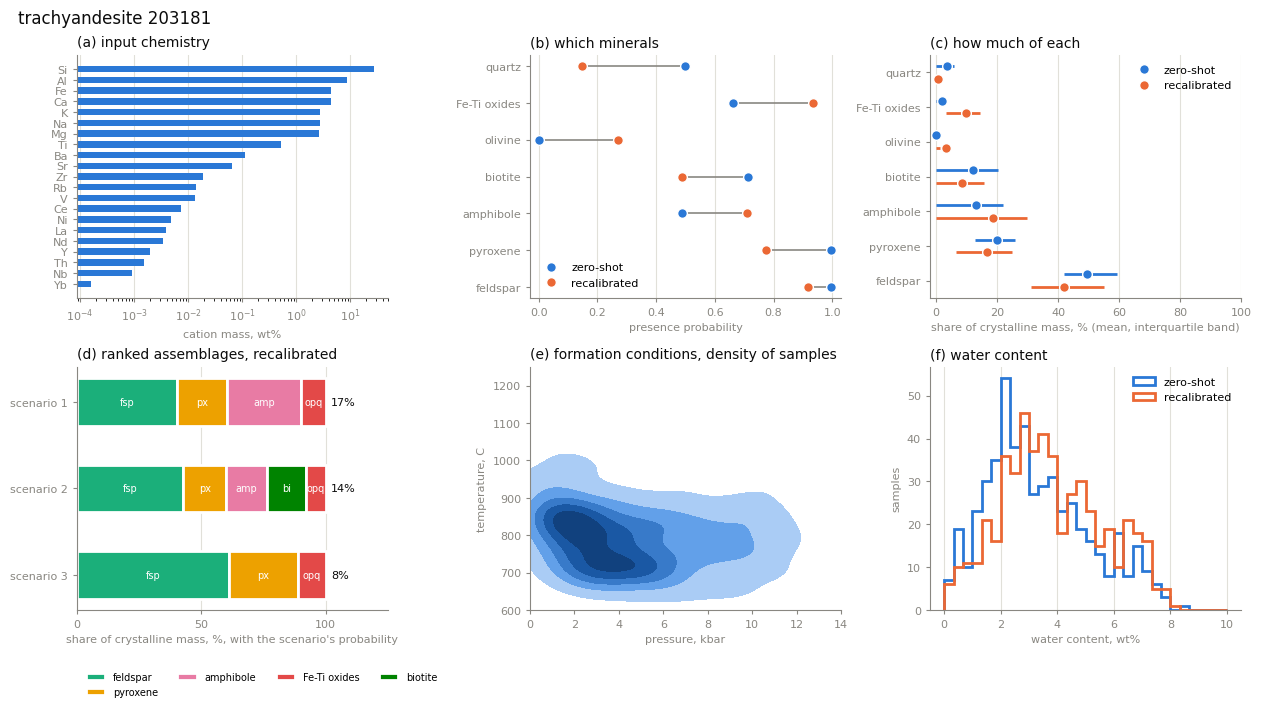

In [11]:
# a library module selected the file-only Agg backend when it was imported above; re-select the notebook backend
%matplotlib inline

ARM_COLOR = {"zero-shot": "#2a78d6", "recalibrated": "#eb6834"}
GROUP_COLOR = dict(zip(GROUPS, ["#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948", "#2a78d6"]))
INK, MUTED, HAIRLINE = "#0b0b0b", "#898781", "#e1e0d9"
DENSITY = LinearSegmentedColormap.from_list("density", ["#cde2fb", "#5598e7", "#1c5cab", "#0d366b"])


def tidy(ax, title):
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=8, length=3)
    ax.grid(True, axis="x", color=HAIRLINE, linewidth=0.8)
    ax.set_axisbelow(True)


def card(rock, i):
    labels = [GROUP_NAME[g] for g in GROUPS]
    y = np.arange(len(GROUPS))
    fig, axes = plt.subplots(2, 3, figsize=(12.5, 7), constrained_layout=True)
    fig.suptitle(rock, x=0.01, ha="left", fontsize=12, color=INK)

    ax = axes[0, 0]
    populated = frac[i] > 0
    order = np.argsort(frac[i][populated])
    ax.barh(np.array([sym for sym, _ in VOCAB])[populated][order], frac[i][populated][order] * 100, color="#2a78d6", height=0.6)
    ax.set_xscale("log")
    ax.set_xlabel("cation mass, wt%", fontsize=8, color=MUTED)
    tidy(ax, "(a) input chemistry")

    ax = axes[0, 1]
    for arm in arms:
        ax.plot(arms[arm][i]["p7"], y, "o", ms=7, color=ARM_COLOR[arm], mec="white", mew=1, label=arm, zorder=3)
    ax.hlines(y, zero_shot[i]["p7"], recalibrated[i]["p7"], color=MUTED, linewidth=1.2, zorder=2)
    ax.set_yticks(y, labels)
    ax.set_xlim(-0.03, 1.03)
    ax.set_xlabel("presence probability", fontsize=8, color=MUTED)
    ax.legend(frameon=False, fontsize=8, loc="lower left")
    tidy(ax, "(b) which minerals")

    ax = axes[0, 2]
    for arm, offset in (("zero-shot", 0.18), ("recalibrated", -0.18)):
        share = arms[arm][i]["share"] * 100
        lo, mid, hi = np.percentile(share, [25, 50, 75], axis=0)
        ax.hlines(y + offset, lo, hi, color=ARM_COLOR[arm], linewidth=2, zorder=2)
        ax.plot(share.mean(0), y + offset, "o", ms=7, color=ARM_COLOR[arm], mec="white", mew=1, label=arm, zorder=3)
    ax.set_yticks(y, labels)
    ax.set_xlim(-2, 100)
    ax.set_xlabel("share of crystalline mass, % (mean, interquartile band)", fontsize=8, color=MUTED)
    ax.legend(frameon=False, fontsize=8, loc="upper right")
    tidy(ax, "(c) how much of each")

    ax = axes[1, 0]
    scenarios = recalibrated[i]["scenarios"]
    named = set()
    for k, sc in enumerate(scenarios):
        left = 0.0
        yk = len(scenarios) - 1 - k
        for g in sc["groups"]:
            s = sc["share"][GROUP_INDEX[g]] * 100
            ax.barh(yk, s, left=left, height=0.55, color=GROUP_COLOR[g], edgecolor="white", linewidth=2,
                    label=None if g in named else GROUP_NAME[g])
            named.add(g)
            if s > 6:
                ax.text(left + s / 2, yk, g, ha="center", va="center", fontsize=7, color="white")
            left += s
        ax.text(left + 2, yk, f"{sc['prob']:.0%}", va="center", fontsize=8, color=INK)
    ax.set_yticks(range(len(scenarios)), [f"scenario {k + 1}" for k in range(len(scenarios))][::-1])
    ax.set_xlim(0, 125)
    ax.set_xticks([0, 50, 100])
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=4)
    ax.set_xlabel("share of crystalline mass, %, with the scenario's probability", fontsize=8, color=MUTED)
    tidy(ax, "(d) ranked assemblages, recalibrated")

    ax = axes[1, 1]
    cond = recalibrated[i]["cond"]
    kde = gaussian_kde(np.vstack([cond["P_kbar"], cond["T"]]))
    pp, tt = np.meshgrid(np.linspace(0, 14, 120), np.linspace(600, 1250, 120))
    z = kde(np.vstack([pp.ravel(), tt.ravel()])).reshape(pp.shape)
    ax.contourf(pp, tt, z, levels=np.linspace(z.max() * 0.08, z.max(), 6), cmap=DENSITY, extend="max")
    ax.set_xlabel("pressure, kbar", fontsize=8, color=MUTED)
    ax.set_ylabel("temperature, C", fontsize=8, color=MUTED)
    tidy(ax, "(e) formation conditions, density of samples")
    ax.grid(False)

    ax = axes[1, 2]
    for arm in arms:
        ax.hist(arms[arm][i]["cond"]["H2O"], bins=np.linspace(0, 10, 31), histtype="step", linewidth=2, color=ARM_COLOR[arm], label=arm)
    ax.set_xlabel("water content, wt%", fontsize=8, color=MUTED)
    ax.set_ylabel("samples", fontsize=8, color=MUTED)
    ax.legend(frameon=False, fontsize=8)
    tidy(ax, "(f) water content")
    return fig


fig = card(rocks.index[1], 1)
display(fig)
plt.close(fig)

Compositions come as a table rather than a panel: CompHead's Dirichlet mean
per mineral, in oxide wt%, for the minerals most likely present. The simulator
carries ferric iron as excess oxygen, recast here to Fe2O3 for display.

In [12]:
from cnmineral.data.magemin_corpus import COMP_OXIDES


def composition_table(i, top=3):
    phases = [SOLID_PHASES[k] for k in np.argsort(-p21_recal[i])[:top]]
    mean = comp_alpha[i].astype(float) / comp_alpha[i].sum(-1, keepdims=True) * 100
    table = pd.DataFrame(mean, index=SOLID_PHASES, columns=COMP_OXIDES).loc[phases]
    table["Fe2O3"] = table["O"] * 159.688 / 15.999
    table["FeO"] = (table["FeO"] - table["O"] * 2 * 71.844 / 15.999).clip(lower=0)
    return table.drop(columns="O").round(2)


composition_table(1)

,SiO2,Al2O3,CaO,MgO,FeO,K2O,Na2O,TiO2,Cr2O3,H2O,Fe2O3
plag,59.11,25.71,8.29,0.04,0.00,0.32,6.31,0.04,0.04,0.04,0.43
spl,0.11,1.56,0.11,1.97,29.86,0.11,0.11,1.30,0.10,0.11,64.68
cpx,52.53,1.47,18.02,10.92,8.62,0.55,2.07,0.56,0.08,0.08,5.10


## 6. The per-rock record

What an app ships per rock, both arms side by side. Presence and shares are
per group; conditions are the raw samples (the front end draws the density);
compositions are per mineral. Everything is plain lists, so it serializes to
JSON as is. A batch of dozens of rocks is a loop over this.

In [13]:
def record(i):
    out = {"rock": rocks.index[i], "groups": [GROUP_NAME[g] for g in GROUPS], "arms": {}}
    for arm, posts in arms.items():
        post = posts[i]
        share = post["share"] * 100
        out["arms"][arm] = {
            "presence": post["p7"].round(3).tolist(),
            "share_mean": share.mean(0).round(1).tolist(),
            "share_p25": np.percentile(share, 25, axis=0).round(1).tolist(),
            "share_p75": np.percentile(share, 75, axis=0).round(1).tolist(),
            "scenarios": [{"groups": [GROUP_NAME[g] for g in sc["groups"]], "prob": round(sc["prob"], 3),
                           "share": (sc["share"] * 100).round(1).tolist()} for sc in post["scenarios"]],
            "conditions": {axis: post["cond"][axis].round(1).tolist() for axis in COND_AXES},
        }
    out["composition_wt_pct"] = composition_table(i).to_dict(orient="index")
    return out


text = json.dumps(record(1))
print(f"{len(text) / 1024:.0f} KB per rock; keys: {list(record(1)['arms']['recalibrated'])}")
print(text[:400], "...")

19 KB per rock; keys: ['presence', 'share_mean', 'share_p25', 'share_p75', 'scenarios', 'conditions']
{"rock": "trachyandesite 203181", "groups": ["feldspar", "pyroxene", "amphibole", "biotite", "olivine", "Fe-Ti oxides", "quartz"], "arms": {"zero-shot": {"presence": [0.996, 0.994, 0.488, 0.714, 0.001, 0.661, 0.498], "share_mean": [49.5, 20.0, 13.0, 12.0, 0.0, 1.8, 3.6], "share_p25": [41.8, 12.7, 0.0, 0.0, 0.0, 0.0, 0.0], "share_p75": [59.2, 25.7, 22.0, 20.3, 0.0, 2.8, 6.0], "scenarios": [{"groups ...


## Where this goes

- The stable inference API (issue #70) replaces sections 1 to 4 with one
  library call that returns the record above; an app should import the
  library rather than copy this notebook.
- The saved recalibrator belongs beside the heads checkpoint once that call
  exists; until then the fit above is the production fit (matrix tier, weight
  decay 1.0, the 372-rock train split).
- Model internals: `docs/encoder.md` and `docs/heads.md`; the overview deck
  in `slides/` has an anatomy slide per head with parameter counts.